<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_ICSIntrusionDetection_Dilek2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Variational Quantum Classifier for ICS intrusion detection: Dilek, Cakin and Oracevic (2025) step by step

This notebook re-implements, runs and checks the method of

> Selma Dilek, Alperen Cakin and Alma Oracevic, "Towards Quantum-Enhanced Intrusion Detection in Industrial Control
> Systems: A Proof-of-Concept Using Variational Quantum Classifiers",
> *2025 International Symposium on Networks, Computers and Communications (ISNCC)*, IEEE, 2025.
> DOI 10.1109/ISNCC66965.2025.11250507

The paper publishes no code. Everything below is written from its four-page description (Sections III and IV).

**What the notebook does.** It downloads the public WUSTL-IIoT-2018 dataset (also called WUSTL-SCADA-2018: Modbus/TCP
traffic of a water-storage SCADA testbed, 7 million network flows, about 6 % of them attacks), draws the paper's small
1,000-flow experiment from it, standardises six flow features, oversamples the minority class in the training split,
and trains Qiskit's `VQC` (a `ZZFeatureMap` followed by a one-layer `RealAmplitudes` ansatz, optimised with COBYLA) on a
quantum simulator. It then measures accuracy, precision, recall, F1 and AUC-ROC, repeats the 5-fold cross-validation
the paper mentions, and compares everything with the paper's Table II. Classical baselines (RBF-SVM, random forest,
logistic regression and the trivial majority-class rule) are trained on exactly the same six standardised features.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned versions of Qiskit; if Colab asks to restart the session, restart and run all again. No GPU, no quantum-cloud account
and no Hugging Face token are needed: the dataset is a public file on the creators' web server (about 200 MB, read in
chunks, only a small random pool of flows is kept and the raw file is deleted afterwards).

**Runtime.** `FAST_MODE = True`: about 7 minutes on a shared laptop CPU (one split, 30 COBYLA iterations, 2-fold check).
`FAST_MODE = False`: about 65 minutes (three different 1,000-flow draws with 100 COBYLA iterations, 5-fold cross-validation, one extra run with [0, pi]-scaled angles).
The committed notebook contains the outputs of the full run (`FAST_MODE = False`, 65 minutes on a heavily shared laptop CPU; the training cell alone is about 8 minutes per fit).

**What you get at the end.** The class distribution of the real dataset, 2-D scatter plots of real flows coloured by their
ground-truth label, the drawing of the circuit that is actually executed, the loss curve (the paper's Fig. 3), the
confusion matrix and ROC curve, the cross-validation table, and a table that puts each number of the paper next to ours with
a verdict per claim.

## The paper in one page

**Problem.** Decide for each network flow of an industrial control system (ICS) whether it is normal traffic or an
attack. The attacks of the WUSTL-IIoT-2018 dataset are reconnaissance attacks on a Modbus/TCP server (port scan, address
scan, device identification, aggressive device identification, exploit that reads coil values).

**Decision.** A variational quantum classifier (VQC) simulated with Qiskit. The paper reports it beats its own earlier
classical Conditional Variational Autoencoder (CVAE-ID) on a small subset of the data.

**Method (Section III, Fig. 2).** Six flow features (`Sport, TotPkts, TotBytes, SrcPkts, DstPkts, SrcBytes`) ->
resampling (minority class oversampled to the majority count) -> `StandardScaler` -> 80/20 train/test split ->
`ZZFeatureMap` (one feature per qubit, so six qubits) -> `RealAmplitudes` ansatz, one layer -> COBYLA minimising the VQC
objective, with a callback that logs the objective -> accuracy, precision, recall, F1 and AUC-ROC.

**Data.** WUSTL-IIoT-2018: 627 MB, "over 7 million observations", 93.93 % normal and 6.07 % attack; column `Target`
(0 normal, 1 attack). Because of the simulation cost the experiment uses **1,000 entries**.

**Claims (Table II, Fig. 3 and Section IV-B).**

| Claim | Paper |
|---|---|
| VQC-ID on the 1,000-entry subset | accuracy 0.9900, precision 0.8667, recall 1.0000, F1 0.9286, AUC-ROC 0.9947 |
| CVAE-ID, the classical benchmark (best setting: 512 latent dimensions, 5 epochs) | accuracy 0.9700, precision 0.8000, recall 0.6667, F1 0.7273, AUC-ROC 0.9894 |
| 5-fold cross-validation of VQC-ID | mean accuracy 98.94 %, recall 1.0 in every fold |
| Convergence (Fig. 3) | objective value stabilises after about 60 iterations |
| Cost | VQC-ID 205.87 s on a CPU simulator, CVAE-ID 3.12 s on a GPU (about 66 times slower) |

The confusion matrix implied by Table II tells us something the text leaves out: 99 % accuracy with precision 0.8667 and
recall 1.0 on a 200-flow test set means 13 attacks, all found, plus 2 false alarms and 185 correct normals. So the test set
holds roughly 6.5 % attacks, i.e. it keeps the natural class ratio, and the oversampling can only have been applied to the
training part (see the table below).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset, features, label | WUSTL-IIoT-2018, six features, `Target` | same file (`wustl-scada-2018.csv`), same six features and label |
| Which 1,000 entries | "a smaller dataset of 1000 entries", not stated | CHOICE: 1,000 flows drawn at random with the natural attack share (57 attacks and 943 normal flows with the file's own share of 5.73 % attacks), one draw per seed (the first 2,000 rows of the file are all normal, so a random draw is the only reading that gives attacks) |
| Order of resampling and split | listed as resampling, scaling, split; "attack instances entirely confined to the testing set" | CHOICE: split first (stratified 80/20, so the test set keeps the natural ratio that Table II implies), then oversample the training minority class, fit the scaler on the oversampled training set only. Doing the resampling before the split would copy attack rows into the test set |
| Oversampling method | "minority class instances oversampled to match the majority" | random duplication with replacement (`sklearn.utils.resample`) |
| Scaler | `StandardScaler` | same, fitted on the training split only; test values are not clipped |
| Feature map | `ZZFeatureMap`, dimension = number of features | `zz_feature_map(6, reps=2, entanglement="full")`, the defaults of Qiskit's `ZZFeatureMap` |
| Ansatz | `RealAmplitudes`, "a single layer" | `real_amplitudes(6, reps=1)` (12 trainable parameters); entanglement left at Qiskit's default `reverse_linear` |
| Optimiser | COBYLA | COBYLA, `maxiter` = 100 in the full run (the paper does not state it; its Fig. 3 flattens after ~60) |
| Loss, read-out | Qiskit `VQC` defaults | cross-entropy on one-hot labels, bit-string -> class by Qiskit's default interpretation |
| Simulator and shots | "quantum simulators", not stated | CHOICE: exact output probabilities from the `qiskit_aer` statevector simulator (the infinite-shot limit, which is what Qiskit's reference `Sampler` of the paper's era returned), wrapped as a small sampler primitive; set `SHOTS = 1024` for a finite-shot, seeded `SamplerV2` (about 10 times slower here) |
| Random seed | not stated | `SEED = 42` (+ 43, 44 for repeated draws) |
| Classical benchmark | CVAE-ID (TensorFlow, ROCm GPU, own earlier work) | NOT re-implemented (no code, no TensorFlow here); replaced by RBF-SVM, random forest and logistic regression on identical inputs |
| Cross-validation | 5-fold, no details | `StratifiedKFold(5)` on the 1,000-flow draw; oversampling and scaling inside each fold |

In [1]:
# Installs. Pinned to the versions this notebook was tested with. Guarded so that nothing is reinstalled locally.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
try:
    import qiskit, qiskit_aer, qiskit_machine_learning
    _ok = (qiskit.__version__ == "2.5.2")
except Exception:
    _ok = False
if IN_COLAB or not _ok:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-machine-learning==0.9.1",
                           "qiskit-aer==0.17.2", "pylatexenc"])
    print("Installed pinned Qiskit. If Colab asks for a session restart, restart and run all again.")
else:
    print("Pinned Qiskit stack already present, nothing to install.")

Pinned Qiskit stack already present, nothing to install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False         # True: class demo (one split, 30 COBYLA iterations, 2-fold check). False: full run (see below).
SEED      = 42            # CHOICE: the paper does not state a seed
IBM_TOKEN = ""            # not used: the paper ran on a simulator; no real-hardware cell in this notebook

# --- paper parameters (Section III and IV) ---
N_QUBITS   = 6            # paper: one qubit per feature, six features
N_ROWS     = 1000         # paper: a smaller dataset of 1000 entries
TEST_SIZE  = 0.20         # paper: 80-20 split
FM_REPS    = 2            # CHOICE: ZZFeatureMap default repetitions
ANSATZ_REPS = 1           # paper: RealAmplitudes with a single layer
SHOTS      = None         # CHOICE: None = exact output probabilities (infinite shots, like Qiskit's reference Sampler); an int = finite-shot seeded Aer sampler
FEATURES   = ["Sport", "TotPkts", "TotBytes", "SrcPkts", "DstPkts", "SrcBytes"]
LABEL      = "Target"

if FAST_MODE:
    SEEDS          = [42]               # one 1,000-flow draw
    COBYLA_MAXITER = 30                 # CHOICE: small budget for a class demo
    CV_FOLDS       = 2                  # reduced from the paper's 5
else:
    SEEDS          = [42, 43, 44]           # three different 1,000-flow draws (CHOICE: limited by CPU time; the VQC fit costs ~7 min each)
    COBYLA_MAXITER = 100                    # CHOICE: Fig. 3 of the paper flattens after ~60 iterations
    CV_FOLDS       = 5                      # paper: 5-fold cross-validation

RUN_ABLATION = not FAST_MODE    # extra run with angles scaled to [0, pi] (not in the paper)

# --- data ---
DATA_DIR    = "qc228_data"    # cache folder (the pool of flows, a few MB)
DATA_PATH    = None            # or the path of an uploaded wustl-scada-2018.csv (raw file, ~200 MB)
KEEP_RAW     = False           # delete the raw ~200 MB CSV once the pool is built
POOL_PER_CLASS = 20000         # CHOICE: random pool of flows kept per class (draws of 1,000 flows come from this pool)
CHUNK        = 500_000         # rows per chunk when streaming the 7-million-row CSV
WUSTL_URL    = "https://www.cse.wustl.edu/~jain/iiot/ftp/wustl-scada-2018.csv"

In [3]:
import os, io, time, warnings, requests, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)

import qiskit, qiskit_machine_learning
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_aer.primitives import SamplerV2 as AerSamplerV2
import qiskit_aer

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| qiskit-aer", qiskit_aer.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print(f"FAST_MODE={FAST_MODE} | seeds={SEEDS} | COBYLA maxiter={COBYLA_MAXITER} | CV folds={CV_FOLDS} | shots={SHOTS or 'exact probabilities'}")

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE=False | seeds=[42, 43, 44] | COBYLA maxiter=100 | CV folds=5 | shots=exact probabilities


## 1. Getting the data

The creators host the dataset as one CSV (`wustl-scada-2018.csv`, about 200 MB, 7 columns: the six features and `Target`).
The code below streams it in chunks of 500,000 rows and, while doing so,

* counts every flow of each class exactly (these are the real class counts of the whole dataset), and
* keeps a uniformly random **pool** of `POOL_PER_CLASS` flows of each class (every row gets a random key and the pool keeps
  the largest keys, which is a uniform sample without replacement).

The 1,000-flow experiments of the paper are then drawn from this pool with the natural attack share. The pool is cached
(a few MB), the raw file is deleted. The web server's certificate chain is incomplete, so if the verified download fails the
code retries once with certificate verification switched off **for this one host only** (the file is public and carries no
secret; it is checked by its row count and class counts below).

In [4]:
POOL_PATH = os.path.join(DATA_DIR, "wustl_pool.csv")
COUNT_PATH = os.path.join(DATA_DIR, "wustl_counts.csv")
RAW_PATH = DATA_PATH or os.path.join(DATA_DIR, "wustl-scada-2018.csv")

def download_raw(path):
    try:
        r = requests.get(WUSTL_URL, stream=True, timeout=120); r.raise_for_status(); how = "verified TLS"
    except requests.exceptions.SSLError:
        import urllib3; urllib3.disable_warnings()
        r = requests.get(WUSTL_URL, stream=True, timeout=120, verify=False); r.raise_for_status()   # ONLY for this host
        how = "TLS verification skipped for cse.wustl.edu (certificate chain incomplete)"
    n = 0
    with open(path, "wb") as f:
        for part in r.iter_content(1 << 20):
            f.write(part); n += len(part)
    print(f"downloaded {n/1e6:.1f} MB; {how}")

def build_pool(raw_path):
    gen = np.random.default_rng(SEED)
    counts = {0: 0, 1: 0}; pools = {0: None, 1: None}
    for chunk in pd.read_csv(raw_path, chunksize=CHUNK):
        chunk.columns = [c.strip() for c in chunk.columns]
        chunk = chunk[FEATURES + [LABEL]].apply(pd.to_numeric, errors="coerce").dropna()
        chunk["_key"] = gen.random(len(chunk))
        for k in (0, 1):
            sub = chunk[chunk[LABEL] == k]
            counts[k] += len(sub)
            pools[k] = sub if pools[k] is None else pd.concat([pools[k], sub])
            pools[k] = pools[k].nlargest(POOL_PER_CLASS, "_key")
    pool = pd.concat([pools[0], pools[1]]).drop(columns="_key").reset_index(drop=True)
    return pool, counts

if not (os.path.exists(POOL_PATH) and os.path.exists(COUNT_PATH)):
    if not os.path.exists(RAW_PATH):
        t0 = time.perf_counter(); download_raw(RAW_PATH); print(f"download took {time.perf_counter()-t0:.0f} s")
    t0 = time.perf_counter()
    pool, counts = build_pool(RAW_PATH)
    pool.to_csv(POOL_PATH, index=False)
    pd.Series(counts).rename("flows").to_csv(COUNT_PATH)
    print(f"streamed the whole file in {time.perf_counter()-t0:.0f} s")
    if not KEEP_RAW and DATA_PATH is None and os.path.exists(RAW_PATH):
        os.remove(RAW_PATH); print("raw file deleted")
else:
    print("using cached pool", POOL_PATH)

pool = pd.read_csv(POOL_PATH)
class_counts = pd.read_csv(COUNT_PATH, index_col=0)["flows"].to_dict()
class_counts = {int(k): int(v) for k, v in class_counts.items()}
N_TOTAL = sum(class_counts.values())
ATTACK_SHARE = class_counts[1] / N_TOTAL
print("whole dataset: %d flows | normal %d (%.2f %%) | attack %d (%.2f %%)" % (N_TOTAL, class_counts[0], 100*class_counts[0]/N_TOTAL, class_counts[1], 100*ATTACK_SHARE))
print("paper: 'over 7 million observations', 93.93 % normal and 6.07 % attack")
print("pool shape:", pool.shape, "| pool class counts:", pool[LABEL].value_counts().to_dict())

using cached pool qc228_data\wustl_pool.csv


whole dataset: 7037983 flows | normal 6634581 (94.27 %) | attack 403402 (5.73 %)
paper: 'over 7 million observations', 93.93 % normal and 6.07 % attack
pool shape: (40000, 7) | pool class counts: {0: 20000, 1: 20000}


## 2. Cleaning, the 1,000-flow draw, split, resampling and scaling (Section III-A)

`make_experiment(seed)` does what the paper's preprocessing paragraph describes, in the order that is consistent with its
Table II (see the choice table above):

1. draw 1,000 flows from the pool with the natural attack share of the file (5.73 %, so 57 attacks and 943 normal flows; the paper's text quotes 6.07 %, the file we downloaded has 5.73 %);
2. stratified 80/20 train/test split (test set: 200 flows, 11 attacks);
3. oversample the training attacks (with replacement) until both classes have the same count (754 normal + 754 attack, the 754 attacks being only 46 distinct flows);
4. `StandardScaler` fitted on the training set only, applied to train and test. The standardised features are fed to the
   circuit directly as rotation angles, as in the paper (no min-max scaling to [0, pi] and no clipping).

In [5]:
def draw_flows(seed, n=N_ROWS):
    # CHOICE: natural attack share, uniformly random flows from the pool
    n_att = int(round(n * ATTACK_SHARE)); n_norm = n - n_att
    g = np.random.default_rng(seed)
    a = pool[pool[LABEL] == 1].sample(n_att, random_state=int(g.integers(1 << 31)))
    b = pool[pool[LABEL] == 0].sample(n_norm, random_state=int(g.integers(1 << 31)))
    return pd.concat([a, b]).sample(frac=1.0, random_state=seed).reset_index(drop=True)

def oversample_and_scale(Xtr, ytr, Xte, seed):
    # oversample the training minority class (with replacement) to the majority count, then fit the scaler on the training set only
    idx1 = np.where(ytr == 1)[0]; idx0 = np.where(ytr == 0)[0]
    minority, majority = (idx1, idx0) if len(idx1) < len(idx0) else (idx0, idx1)
    extra = resample(minority, replace=True, n_samples=len(majority) - len(minority), random_state=seed)
    keep = np.concatenate([majority, minority, extra])
    Xb, yb = Xtr[keep], ytr[keep]
    sc = StandardScaler().fit(Xb)
    return sc.transform(Xb), yb, sc.transform(Xte), sc

def make_experiment(seed):
    df = draw_flows(seed)
    X = df[FEATURES].to_numpy(float); y = df[LABEL].to_numpy(int)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    Ztr, ybal, Zte, sc = oversample_and_scale(Xtr, ytr, Xte, seed)
    return dict(seed=seed, df=df, Xtr_raw=Xtr, ytr_raw=ytr, Xte_raw=Xte, yte=yte, Ztr=Ztr, ytr=ybal, Zte=Zte, scaler=sc)

exp = make_experiment(SEED)
print("1,000-flow draw:", exp["df"].shape, exp["df"][LABEL].value_counts().to_dict())
print("train before oversampling:", np.bincount(exp["ytr_raw"]), "| train after oversampling:", np.bincount(exp["ytr"]), "| test:", np.bincount(exp["yte"]))
print("scaler fitted on the training set only; test column means (should be near, not exactly, 0):", np.round(exp["Zte"].mean(0), 2))

1,000-flow draw: (1000, 7) {0: 943, 1: 57}
train before oversampling: [754  46] | train after oversampling: [754 754] | test: [189  11]
scaler fitted on the training set only; test column means (should be near, not exactly, 0): [0.56 0.56 0.16 0.52 0.6  0.11]


## Dataset Exploration and Visualisation

Everything in this section is computed from the real WUSTL-IIoT-2018 flows; nothing is simulated or invented. The dataset
file has only a **binary** label (`Target`: 0 normal, 1 attack): the five attack types named in the paper (port scan, address
scan, device identification, aggressive device identification, exploit) are not given per flow in this file, so a
multi-class colouring is not possible and the plots use the two ground-truth classes.

In [6]:
# shape, feature names, original label values and counts
print("dataset shape (whole file): (%d, %d)  -> %d feature columns + the label column '%s'" % (N_TOTAL, len(FEATURES) + 1, len(FEATURES), LABEL))
print("feature names:", FEATURES)
print("original label values and counts:", class_counts, " (0 = normal traffic, 1 = attack traffic)")
print("pool kept in memory:", pool.shape, "| 1,000-flow draw:", exp["df"].shape)
print("\nper-class summary of the random pool (real flows):")
display(pool.groupby(LABEL)[FEATURES].describe().T.round(1).iloc[:, :].head(48))
dup = pool.duplicated(keep=False).mean()
print("share of pool rows that have an identical twin (same six features and label): %.1f %%" % (100 * dup))

dataset shape (whole file): (7037983, 7)  -> 6 feature columns + the label column 'Target'
feature names: ['Sport', 'TotPkts', 'TotBytes', 'SrcPkts', 'DstPkts', 'SrcBytes']
original label values and counts: {0: 6634581, 1: 403402}  (0 = normal traffic, 1 = attack traffic)
pool kept in memory: (40000, 7) | 1,000-flow draw: (1000, 7)

per-class summary of the random pool (real flows):


Target                     0        1
Sport    count  2.000000e+04  20000.0
         mean   5.685220e+04  41493.2
         std    7.086100e+03   7342.9
         min    0.000000e+00  32768.0
         25%    5.317000e+04  35458.0
         50%    5.728900e+04  35459.0
         75%    6.139720e+04  50959.0
         max    6.553300e+04  61053.0
TotPkts  count  2.000000e+04  20000.0
         mean   3.880000e+01      3.0
         std    1.352300e+03      1.6
         min    1.000000e+00      2.0
         25%    1.800000e+01      2.0
         50%    2.000000e+01      2.0
         75%    2.000000e+01      4.0
         max    9.575000e+04     22.0
TotBytes count  2.000000e+04  20000.0
         mean   2.251975e+05    192.8
         std    1.652438e+07    106.0
         min    6.000000e+01    124.0
         25%    1.152000e+03    124.0
         50%    1.276000e+03    124.0
         75%    1.276000e+03    248.0
         max    1.656103e+09   1406.0
SrcPkts  count  2.000000e+04  20000.0
         mean   2.950000e+01      2.1
         std    1.352300e+03      0.7
         min    1.000000e+00      2.0
         25%    1.000000e+01      2.0
         50%    1.000000e+01      2.0
         75%    1.000000e+01      2.0
         max    9.575000e+04     12.0
DstPkts  count  2.000000e+04  20000.0
         mean   1.030000e+01      1.0
         std    6.880000e+01      1.1
         min    0.000000e+00      0.0
         25%    8.000000e+00      0.0
         50%    1.000000e+01      0.0
         75%    1.000000e+01      2.0
         max    4.858000e+03     10.0
SrcBytes count  2.000000e+04  20000.0
         mean   2.175800e+03    132.6
         std    9.779810e+04     48.0
         min    6.000000e+01    124.0
         25%    6.440000e+02    124.0
         50%    6.440000e+02    124.0
         75%    6.440000e+02    124.0
         max    6.921984e+06    782.0

share of pool rows that have an identical twin (same six features and label): 64.6 %


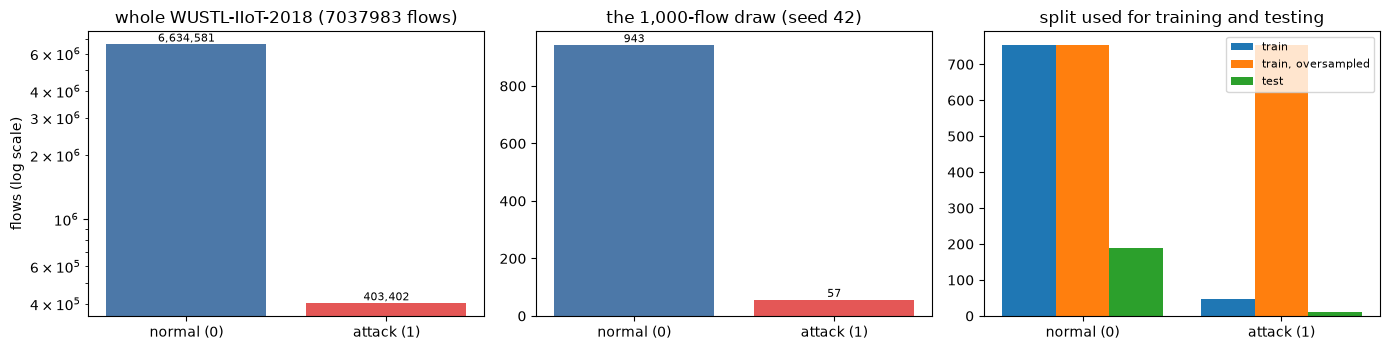

In [7]:
# class distribution: whole dataset (log scale), the 1,000-flow draw, and the experiment's train / oversampled train / test split
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].bar(["normal (0)", "attack (1)"], [class_counts[0], class_counts[1]], color=["#4c78a8", "#e45756"])
ax[0].set_yscale("log"); ax[0].set_title("whole WUSTL-IIoT-2018 (%d flows)" % N_TOTAL); ax[0].set_ylabel("flows (log scale)")
for i, k in enumerate((0, 1)): ax[0].text(i, class_counts[k], f"{class_counts[k]:,}", ha="center", va="bottom", fontsize=8)
d = exp["df"][LABEL].value_counts().sort_index()
ax[1].bar(["normal (0)", "attack (1)"], d.values, color=["#4c78a8", "#e45756"]); ax[1].set_title("the 1,000-flow draw (seed %d)" % SEED)
for i, v in enumerate(d.values): ax[1].text(i, v, str(v), ha="center", va="bottom", fontsize=8)
w = 0.27; xs = np.arange(2)
for j, (nm, arr) in enumerate([("train", exp["ytr_raw"]), ("train, oversampled", exp["ytr"]), ("test", exp["yte"])]):
    ax[2].bar(xs + (j - 1) * w, np.bincount(arr, minlength=2), w, label=nm)
ax[2].set_xticks(xs); ax[2].set_xticklabels(["normal (0)", "attack (1)"]); ax[2].legend(fontsize=8); ax[2].set_title("split used for training and testing")
plt.tight_layout(); plt.show()

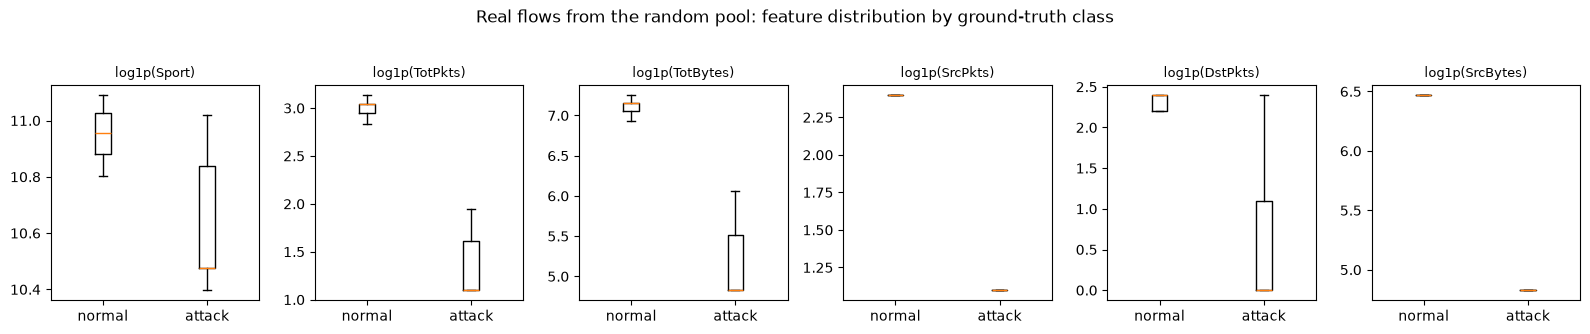

In [8]:
# feature distributions per real class (log1p scale: packet and byte counts are heavy-tailed)
fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
for a, f in zip(axes, FEATURES):
    data = [np.log1p(pool.loc[pool[LABEL] == k, f].clip(lower=0)) for k in (0, 1)]
    a.boxplot(data, showfliers=False); a.set_xticklabels(["normal", "attack"]); a.set_title(f"log1p({f})", fontsize=9)
plt.suptitle("Real flows from the random pool: feature distribution by ground-truth class", y=1.03); plt.tight_layout(); plt.show()

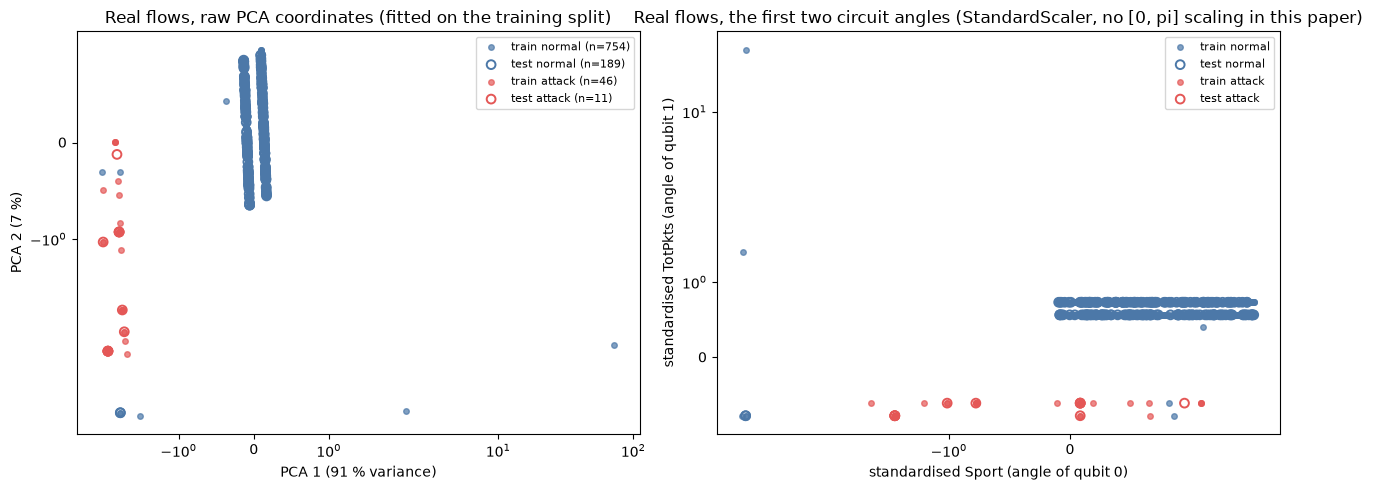

PCA explained variance of the first two components: [0.912 0.075]
range of the standardised angles (train): min -4.95, max 38.35; (test): min -4.78, max 1.52  -> far outside [0, pi] for the heavy-tailed byte and packet counts


In [9]:
# 2-D scatter of real flows coloured by ground-truth label.
# (a) raw PCA coordinates of the standardised training flows (PCA fitted on the training split only; the training split is shown
#     before oversampling so that every point is one real flow); test flows projected with the same PCA are shown as hollow marks.
# (b) the first two standardised features Sport and TotPkts, i.e. exactly the angles the first two qubits receive.
Xs_tr = exp["scaler"].transform(exp["Xtr_raw"]); Xs_te = exp["Zte"]
pca = PCA(n_components=2, random_state=SEED).fit(Xs_tr)
P_tr, P_te = pca.transform(Xs_tr), pca.transform(Xs_te)
colors = {0: "#4c78a8", 1: "#e45756"}; names = {0: "normal", 1: "attack"}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k in (0, 1):
    m = exp["ytr_raw"] == k; ax[0].scatter(P_tr[m, 0], P_tr[m, 1], s=16, c=colors[k], alpha=0.7, label=f"train {names[k]} (n={m.sum()})")
    m = exp["yte"] == k;    ax[0].scatter(P_te[m, 0], P_te[m, 1], s=40, facecolors="none", edgecolors=colors[k], linewidths=1.4, label=f"test {names[k]} (n={m.sum()})")
ax[0].set_xlabel("PCA 1 (%.0f %% variance)" % (100 * pca.explained_variance_ratio_[0])); ax[0].set_ylabel("PCA 2 (%.0f %%)" % (100 * pca.explained_variance_ratio_[1]))
ax[0].set_title("Real flows, raw PCA coordinates (fitted on the training split)"); ax[0].set_xscale("symlog"); ax[0].set_yscale("symlog"); ax[0].legend(fontsize=8)
for k in (0, 1):
    m = exp["ytr_raw"] == k; ax[1].scatter(Xs_tr[m, 0], Xs_tr[m, 1], s=16, c=colors[k], alpha=0.7, label=f"train {names[k]}")
    m = exp["yte"] == k;    ax[1].scatter(Xs_te[m, 0], Xs_te[m, 1], s=40, facecolors="none", edgecolors=colors[k], linewidths=1.4, label=f"test {names[k]}")
ax[1].set_xlabel("standardised Sport (angle of qubit 0)"); ax[1].set_ylabel("standardised TotPkts (angle of qubit 1)")
ax[1].set_title("Real flows, the first two circuit angles (StandardScaler, no [0, pi] scaling in this paper)"); ax[1].legend(fontsize=8)
ax[1].set_xscale("symlog"); ax[1].set_yscale("symlog")
plt.tight_layout(); plt.show()
print("PCA explained variance of the first two components:", np.round(pca.explained_variance_ratio_, 3))
print("range of the standardised angles (train): min %.2f, max %.2f; (test): min %.2f, max %.2f  -> far outside [0, pi] for the heavy-tailed byte and packet counts" %
      (Xs_tr.min(), Xs_tr.max(), Xs_te.min(), Xs_te.max()))

## 3. Classical baselines on exactly the same inputs

The paper's classical benchmark is its own CVAE-ID (a conditional variational autoencoder, TensorFlow on a GPU); neither its
code nor its trained model is available, so it is not re-implemented. Instead the same standardised, oversampled six-feature
training set and the same 200-flow test set are given to an RBF-SVM, a random forest and a logistic regression. The
majority-class rule (always "normal") shows what 93 to 94 % accuracy means on this class ratio.

In [10]:
def metrics_dict(y, pred, score):
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0),
                auc=roc_auc_score(y, score) if len(np.unique(y)) == 2 else np.nan)

def baseline_models(seed):
    return {"SVC (rbf)": SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=seed),
            "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
            "LogisticRegression": LogisticRegression(max_iter=3000, random_state=seed)}

def run_baselines(e):
    rows, preds = [], {}
    for name, mdl in baseline_models(e["seed"]).items():
        t0 = time.perf_counter(); mdl.fit(e["Ztr"], e["ytr"]); pred = mdl.predict(e["Zte"]); sc = mdl.predict_proba(e["Zte"])[:, 1]
        rows.append(dict(model=name, seconds=time.perf_counter() - t0, **metrics_dict(e["yte"], pred, sc))); preds[name] = pred
    maj = np.zeros_like(e["yte"])
    rows.append(dict(model="majority class (always normal)", seconds=0.0, **metrics_dict(e["yte"], maj, np.zeros(len(maj)))))
    return pd.DataFrame(rows), preds

base_df, base_preds = run_baselines(exp)
display(base_df.round(4).set_index("model"))

,seconds,accuracy,precision,recall,f1,auc
model,,,,,,
SVC (rbf),0.0172,1.000,1.0000,1.0,1.0000,1.0
RandomForest,1.6854,1.000,1.0000,1.0,1.0000,1.0
LogisticRegression,0.0519,0.990,0.8462,1.0,0.9167,1.0
majority class (always normal),0.0000,0.945,0.0000,0.0,0.0000,0.5


## 4. The quantum model: ZZFeatureMap + RealAmplitudes + COBYLA (Section III-B)

Qiskit's `VQC` glues a feature map, an ansatz, a sampler and an optimiser into a classifier trained with cross-entropy on
one-hot labels. The paper's choices are in the configuration cell; `build_vqc` is the single place where the model is
constructed, so the circuit drawn below is exactly the circuit that is trained and evaluated.

In [11]:
from qiskit import transpile
from qiskit.primitives import BaseSamplerV2
from qiskit.primitives.containers import SamplerPubResult, PrimitiveResult, DataBin
from qiskit.primitives.containers.sampler_pub import SamplerPub
from qiskit_aer import AerSimulator

class _ExactData:                                   # what SamplerQNN reads: data.get_counts(i) -> {outcome: probability}
    def __init__(self, probs): self._p = probs
    def get_counts(self, i=None): return self._p[0 if i is None else i]
class _DoneJob:
    def __init__(self, res): self._r = res
    def result(self): return self._r
    def done(self): return True

class ExactProbabilitySampler(BaseSamplerV2):
    '''Sampler primitive that returns the exact output distribution of each circuit (no shot noise).
    The circuit is the one VQC builds (feature map + ansatz + measure_all); the final measurements are replaced by the
    save_probabilities instruction of Aer, so the probabilities are those of measuring all qubits. All distinct parameter
    sets of one call run in one Aer batch (duplicates are simulated once; the result is identical).'''
    def __init__(self, threads=1):
        self._backend = AerSimulator(method="statevector", max_parallel_threads=threads)
        self._cache = {}
    def _prepared(self, circuit):
        if id(circuit) not in self._cache:
            qc = circuit.remove_final_measurements(inplace=False); qc.save_probabilities()
            self._cache[id(circuit)] = (transpile(qc, self._backend, optimization_level=0), circuit)
        return self._cache[id(circuit)][0]
    def run(self, pubs, *, shots=None):
        results = []
        for p in pubs:
            pub = SamplerPub.coerce(p); tqc = self._prepared(pub.circuit)
            params = list(pub.circuit.parameters)
            vals = np.atleast_2d(pub.parameter_values.as_array(params)).reshape(-1, len(params))
            uniq, inverse = np.unique(vals, axis=0, return_inverse=True)       # identical rows (many duplicated flows) are simulated once
            inverse = np.asarray(inverse).reshape(-1)
            pos = {q: i for i, q in enumerate(params)}
            binds = {q: uniq[:, pos[q]].tolist() for q in tqc.parameters}
            res = self._backend.run(tqc, parameter_binds=[binds]).result()
            uprobs = [{int(j): float(v) for j, v in enumerate(np.asarray(res.data(k)["probabilities"], float)) if v > 0} for k in range(uniq.shape[0])]
            probs = [uprobs[i] for i in inverse]
            results.append(SamplerPubResult(DataBin(meas=_ExactData(probs), shape=()), metadata={}))
        return _DoneJob(PrimitiveResult(results))

def make_sampler(seed):
    if SHOTS is None:
        return ExactProbabilitySampler()                    # CHOICE: exact probabilities (no shot noise, no seed needed)
    return AerSamplerV2(default_shots=SHOTS, seed=seed)     # finite shots, seeded

def build_vqc(seed, maxiter=COBYLA_MAXITER, callback=None):
    fm  = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement="full")     # paper: ZZFeatureMap (Qiskit default reps / entanglement)
    ans = real_amplitudes(N_QUBITS, reps=ANSATZ_REPS)                     # paper: RealAmplitudes, a single layer
    return VQC(feature_map=fm, ansatz=ans, optimizer=COBYLA(maxiter=maxiter), sampler=make_sampler(seed), callback=callback)

## Quantum Circuit Architecture

The next cell draws the circuit that the `VQC` object sends to the sampler (feature map, ansatz and the measurement of all
qubits), decomposed to elementary gates, and prints its size.

The paper gives no circuit drawing beyond the block diagram of its Fig. 1. The assumptions it leaves open are: the number of
feature-map repetitions (Qiskit default 2), the feature-map entanglement (Qiskit default "full", i.e. every pair of the
six qubits), the ansatz entanglement (Qiskit's `reverse_linear` default for `RealAmplitudes`), the ansatz repetitions
(the text says "a single layer", read as `reps=1`, which gives a rotation layer, one entangling block and a final rotation
layer), and the read-out (Qiskit `VQC` default: the measured bit string is mapped to a class index).

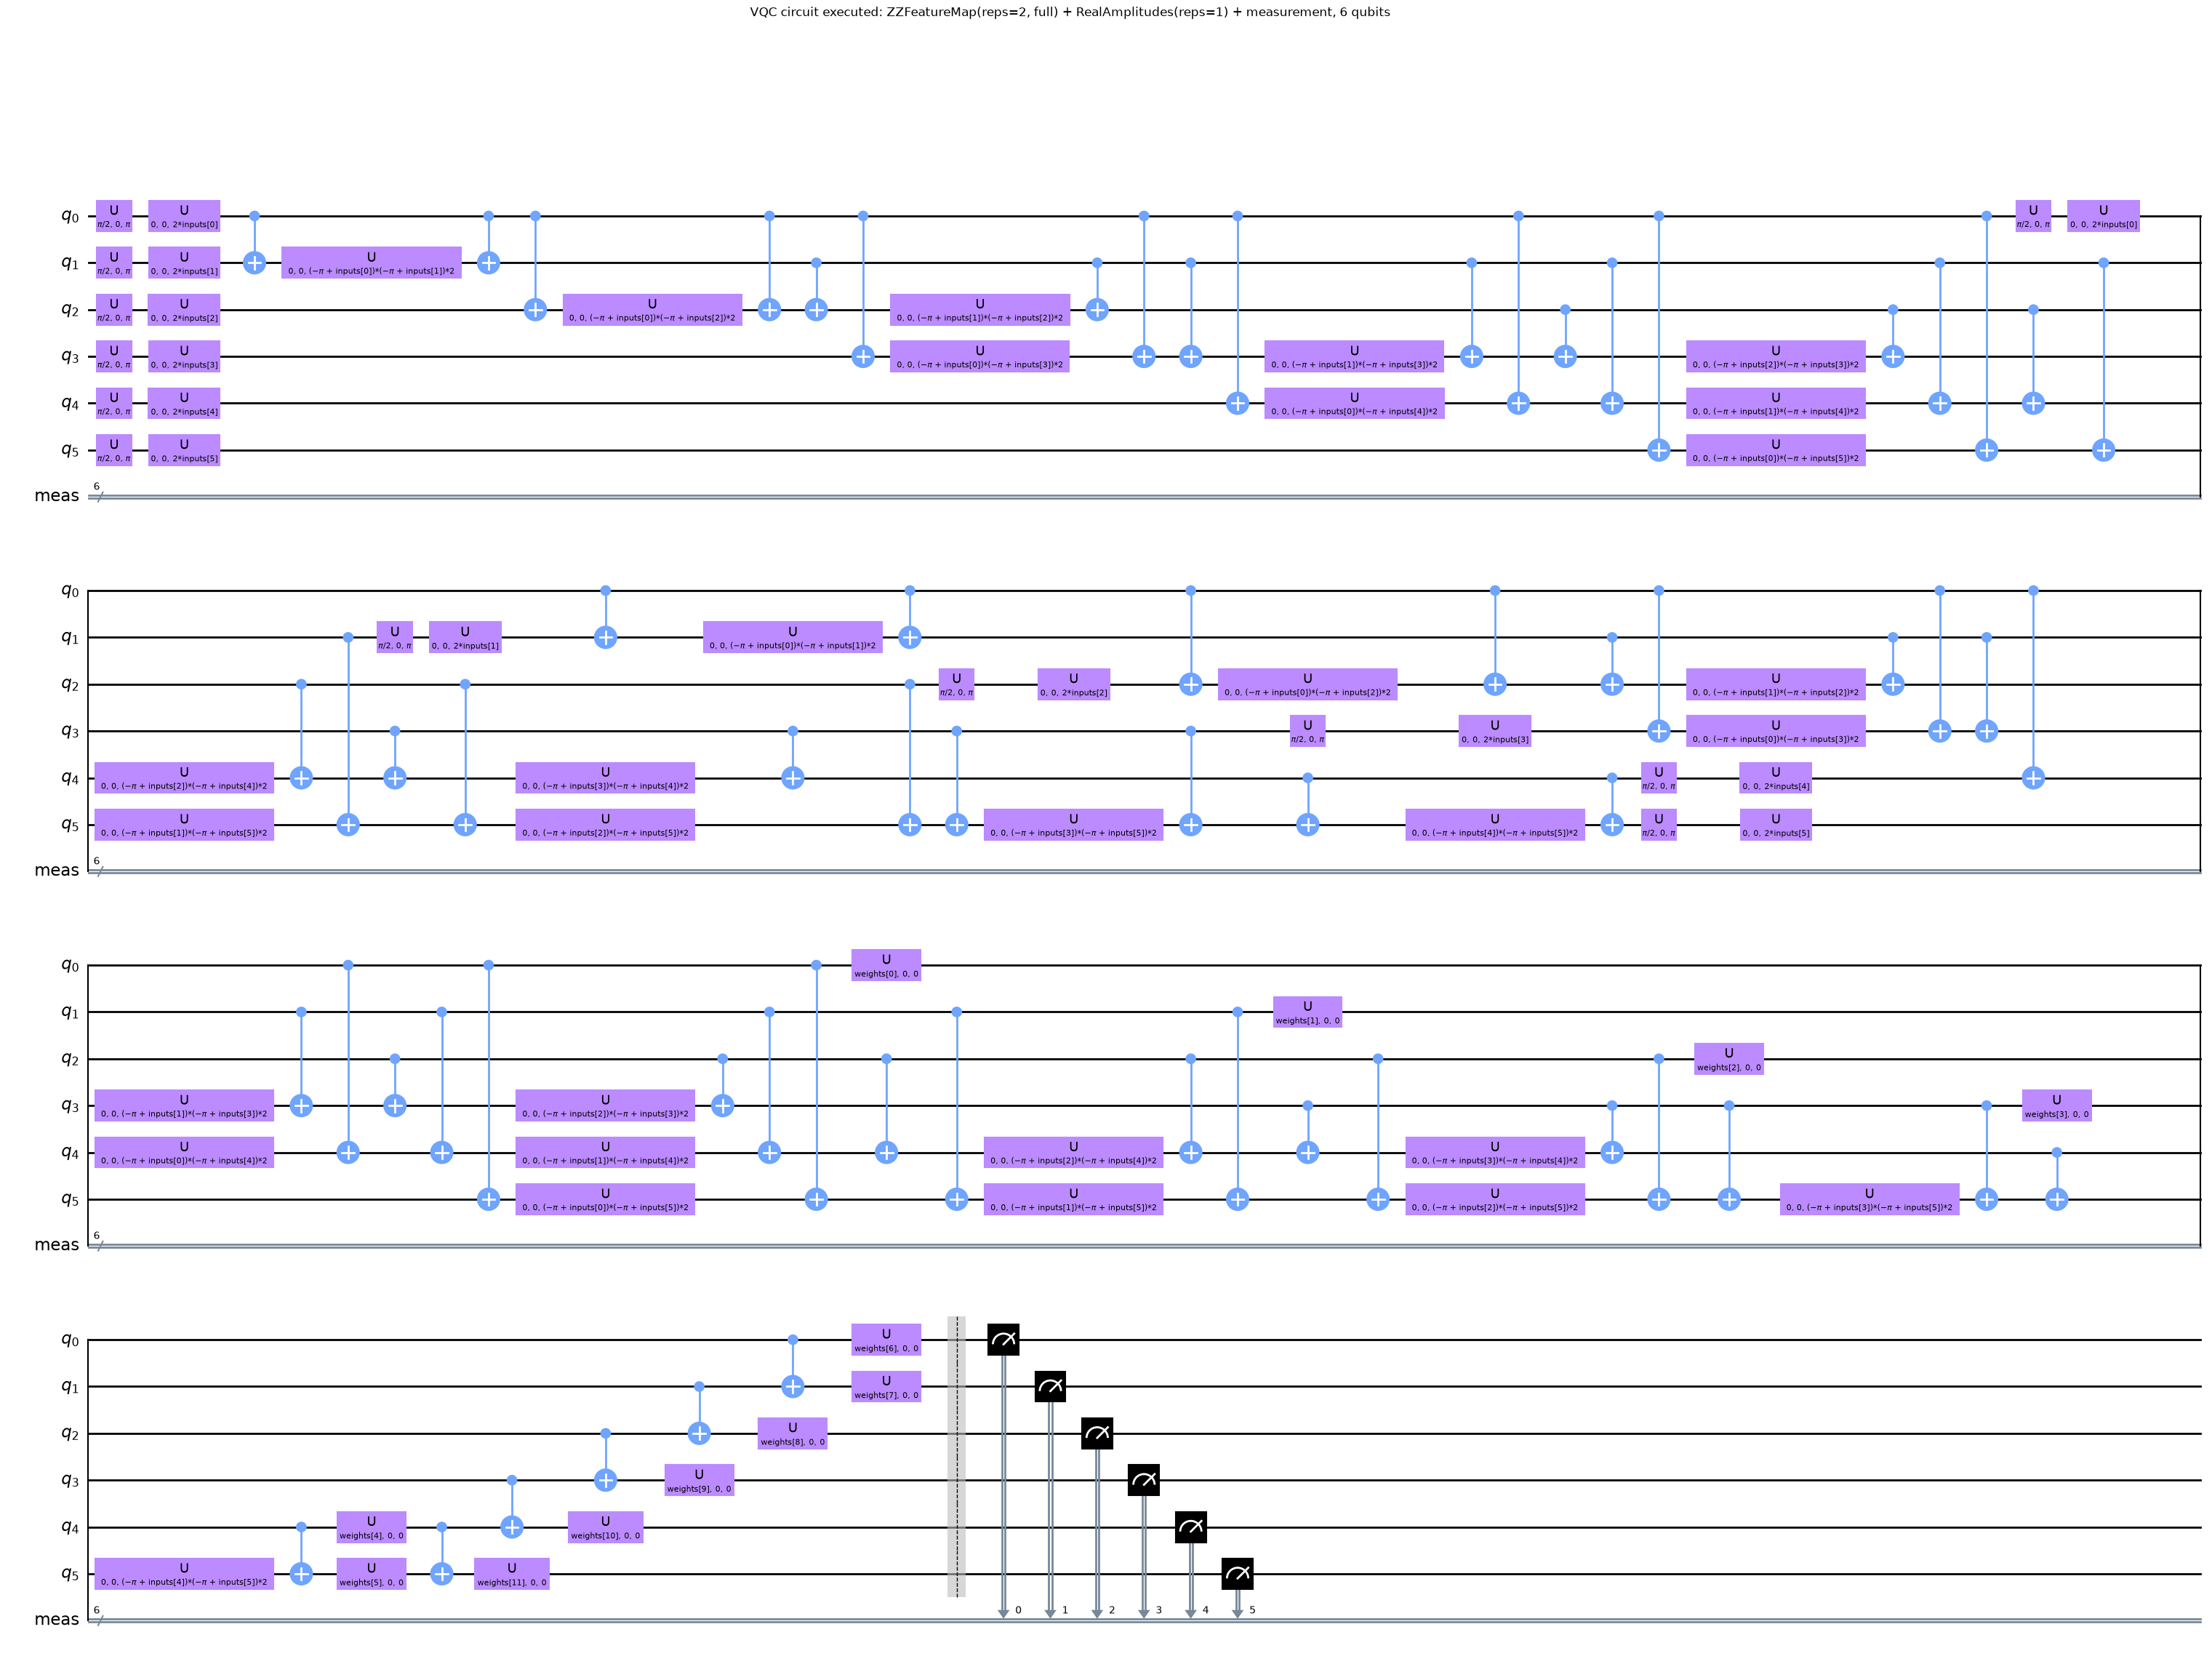

qubits: 6 | depth of the decomposed circuit: 57 | trainable parameters: 12 | input (data) parameters: 6
two-qubit gates: 65 | gate counts: {'u': 66, 'cx': 65, 'measure': 6, 'barrier': 1}


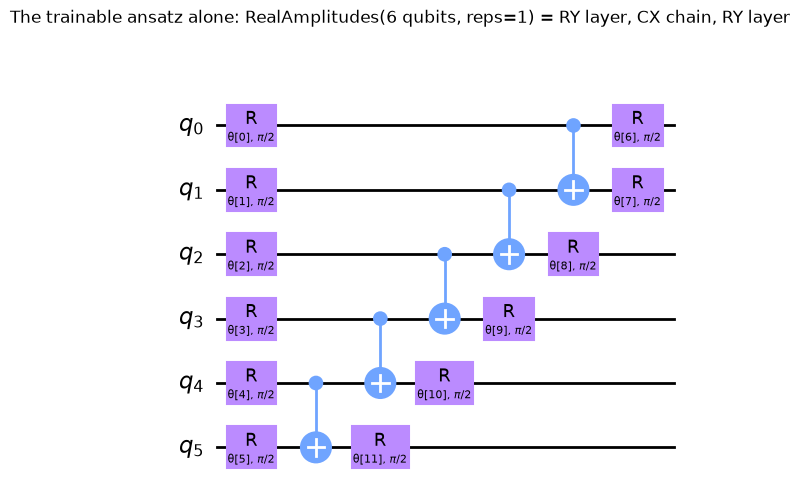

In [12]:
vqc_demo = build_vqc(SEED)
qnn = vqc_demo.neural_network
circ = getattr(qnn, "_circuit", None) or qnn.circuit.measure_all(inplace=False)     # the circuit that is really executed
assert circ.num_qubits == N_QUBITS and qnn.num_inputs == N_QUBITS and qnn.num_weights == 12
assert circ.count_ops().get("measure", 0) == N_QUBITS
dec = circ.decompose(reps=3)
fig = dec.draw("mpl", fold=45, style="clifford")
fig.suptitle(f"VQC circuit executed: ZZFeatureMap(reps={FM_REPS}, full) + RealAmplitudes(reps={ANSATZ_REPS}) + measurement, {N_QUBITS} qubits", y=0.97)
display(fig); plt.close(fig)
ops = dec.count_ops()
print("qubits:", circ.num_qubits, "| depth of the decomposed circuit:", dec.depth(), "| trainable parameters:", qnn.num_weights,
      "| input (data) parameters:", qnn.num_inputs)
print("two-qubit gates:", sum(n for g, n in ops.items() if g in ("cx", "cz")), "| gate counts:", dict(ops))

# the trainable part on its own, to show the ansatz clearly
fig2 = real_amplitudes(N_QUBITS, reps=ANSATZ_REPS).decompose().draw("mpl", style="clifford")
fig2.suptitle("The trainable ansatz alone: RealAmplitudes(6 qubits, reps=1) = RY layer, CX chain, RY layer", y=1.0)
display(fig2); plt.close(fig2)

## 5. Training, with the objective value logged at every evaluation (Fig. 3 of the paper)

COBYLA evaluates the VQC objective (cross-entropy over the whole oversampled training set) once per iteration, so the
callback's list is the paper's Fig. 3: objective value against iterations. Training and prediction are timed together to
compare with the paper's 205.87 s.

VQC trained on 1508 oversampled flows (754 attacks / 754 normal) in 506.6 s with 100 objective evaluations
{'seconds': 506.6155, 'evaluations': 100, 'accuracy': 0.58, 'precision': 0.0989, 'recall': 0.8182, 'f1': 0.1765, 'auc': 0.8586}


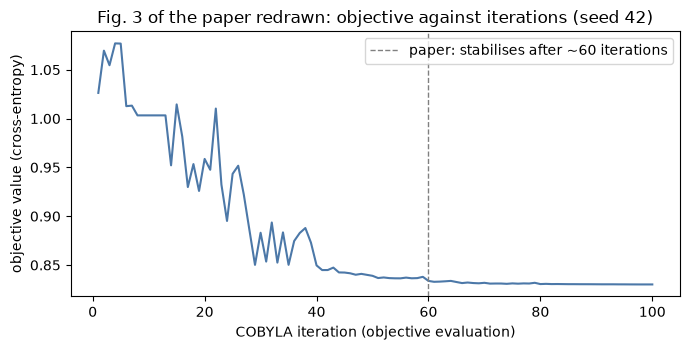

In [13]:
def fit_eval_vqc(e, seed, maxiter=COBYLA_MAXITER, keep_curve=False):
    algorithm_globals.random_seed = seed
    hist = []
    vqc = build_vqc(seed, maxiter, callback=lambda w, loss: hist.append(float(loss)))
    t0 = time.perf_counter()
    vqc.fit(e["Ztr"], e["ytr"])
    proba = vqc.predict_proba(e["Zte"])[:, 1]; pred = vqc.predict(e["Zte"]); secs = time.perf_counter() - t0
    out = dict(seconds=secs, evaluations=len(hist), **metrics_dict(e["yte"], pred, proba))
    return out, pred, proba, hist, vqc

t0 = time.perf_counter()
res0, pred0, proba0, hist0, vqc0 = fit_eval_vqc(exp, SEED)
print("VQC trained on %d oversampled flows (%d attacks / %d normal) in %.1f s with %d objective evaluations"
      % (len(exp["ytr"]), (exp["ytr"] == 1).sum(), (exp["ytr"] == 0).sum(), res0["seconds"], res0["evaluations"]))
print({k: round(v, 4) for k, v in res0.items()})

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(np.arange(1, len(hist0) + 1), hist0, color="#4c78a8")
ax.axvline(60, color="gray", ls="--", lw=1, label="paper: stabilises after ~60 iterations")
ax.set_xlabel("COBYLA iteration (objective evaluation)"); ax.set_ylabel("objective value (cross-entropy)")
ax.set_title("Fig. 3 of the paper redrawn: objective against iterations (seed %d)" % SEED); ax.legend(); plt.tight_layout(); plt.show()

## 6. Test-set results: metrics, confusion matrix and ROC curve (Table II)

Attack is the positive class (precision, recall and F1 are those of the attack class). The 200-flow test set holds only 12
attacks, so one missed or falsely flagged attack moves precision, recall and F1 by several points: read single numbers
with that in mind.

,seconds,evaluations,accuracy,precision,recall,f1,auc
model,,,,,,,
VQC (ZZFeatureMap + RealAmplitudes + COBYLA),506.6155,100.0,0.580,0.0989,0.8182,0.1765,0.8586
SVC (rbf),0.0172,NaN,1.000,1.0000,1.0000,1.0000,1.0000
RandomForest,1.6854,NaN,1.000,1.0000,1.0000,1.0000,1.0000
LogisticRegression,0.0519,NaN,0.990,0.8462,1.0000,0.9167,1.0000
majority class (always normal),0.0000,NaN,0.945,0.0000,0.0000,0.0000,0.5000


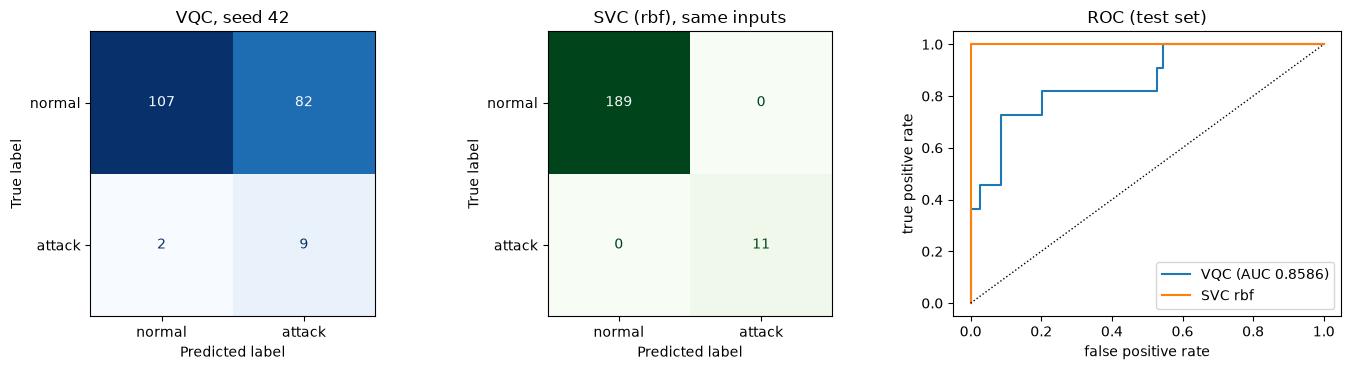

VQC confusion matrix [[TN, FP], [FN, TP]]: [[107, 82], [2, 9]] | the paper's Table II implies [[185, 2], [0, 13]] for its 200-flow test set


In [14]:
tab = pd.concat([pd.DataFrame([dict(model="VQC (ZZFeatureMap + RealAmplitudes + COBYLA)", **res0)]), base_df], ignore_index=True)
display(tab.round(4).set_index("model"))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
cm = confusion_matrix(exp["yte"], pred0, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["normal", "attack"]).plot(ax=ax[0], colorbar=False, cmap="Blues"); ax[0].set_title("VQC, seed %d" % SEED)
cmb = confusion_matrix(exp["yte"], base_preds["SVC (rbf)"], labels=[0, 1])
ConfusionMatrixDisplay(cmb, display_labels=["normal", "attack"]).plot(ax=ax[1], colorbar=False, cmap="Greens"); ax[1].set_title("SVC (rbf), same inputs")
fpr, tpr, _ = roc_curve(exp["yte"], proba0); ax[2].plot(fpr, tpr, label="VQC (AUC %.4f)" % res0["auc"])
svc_p = baseline_models(SEED)["SVC (rbf)"].fit(exp["Ztr"], exp["ytr"]).predict_proba(exp["Zte"])[:, 1]
fpr, tpr, _ = roc_curve(exp["yte"], svc_p); ax[2].plot(fpr, tpr, label="SVC rbf")
ax[2].plot([0, 1], [0, 1], "k:", lw=1); ax[2].set_xlabel("false positive rate"); ax[2].set_ylabel("true positive rate"); ax[2].legend(); ax[2].set_title("ROC (test set)")
plt.tight_layout(); plt.show()
print("VQC confusion matrix [[TN, FP], [FN, TP]]:", cm.tolist(), "| the paper's Table II implies [[185, 2], [0, 13]] for its 200-flow test set")

## 7. Repeated draws and cross-validation (Section IV-B)

The paper fits one model on one 1,000-flow subset and then reports "5-fold cross-validation, average accuracy 98.94 %".
Two checks follow: (a) the whole pipeline on several different random 1,000-flow draws, with a different test set each
time (mean and standard deviation over `SEEDS`); (b) stratified k-fold cross-validation on the main draw, with
oversampling and scaling redone inside every training fold so that nothing leaks into the validation fold.

In [15]:
rep_rows, base_rows = [], []
for s in SEEDS:
    e = exp if s == SEED else make_experiment(s)
    r, _, _, _, _ = (res0, None, None, None, None) if s == SEED else fit_eval_vqc(e, s)
    rep_rows.append(dict(seed=s, model="VQC", **r))
    bdf, _ = run_baselines(e)
    for _, row in bdf.iterrows(): base_rows.append(dict(seed=s, **row.to_dict()))
rep = pd.concat([pd.DataFrame(rep_rows), pd.DataFrame(base_rows).rename(columns={"model": "model"})], ignore_index=True)
summary = rep.groupby("model")[["accuracy", "precision", "recall", "f1", "auc", "seconds"]].agg(["mean", "std"]).round(4)
print("Over %d draw(s) of 1,000 flows (seeds %s), %d test attacks per draw:" % (len(SEEDS), SEEDS, int(round(N_ROWS * ATTACK_SHARE * TEST_SIZE))))
display(summary)

Over 3 draw(s) of 1,000 flows (seeds [42, 43, 44]), 11 test attacks per draw:


accuracy         precision          recall              f1             auc           seconds         
                                   mean     std      mean     std    mean     std    mean     std    mean     std      mean      std
model                                                                                                                               
LogisticRegression               0.9967  0.0058    0.9487  0.0888  1.0000  0.0000  0.9722  0.0481  1.0000  0.0000    0.0323   0.0358
RandomForest                     1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  1.0000  0.0000  1.0000  0.0000    2.2412   0.6888
SVC (rbf)                        1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  1.0000  0.0000  1.0000  0.0000    0.0367   0.0255
VQC                              0.6400  0.0832    0.1168  0.0197  0.8182  0.0909  0.2035  0.0277  0.8453  0.0126  467.6583  40.6494
majority class (always normal)   0.9450  0.0000    0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.5000  0.0000    0.0000   0.0000

In [16]:
# (b) stratified k-fold cross-validation on the main draw
X_all = exp["df"][FEATURES].to_numpy(float); y_all = exp["df"][LABEL].to_numpy(int)
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
cv_rows = []
for fold, (tr, va) in enumerate(skf.split(X_all, y_all), 1):
    Ztr, ybal, Zva, _ = oversample_and_scale(X_all[tr], y_all[tr], X_all[va], SEED + fold)
    fe = dict(seed=SEED + fold, Ztr=Ztr, ytr=ybal, Zte=Zva, yte=y_all[va])
    r, p, pr, _, _ = fit_eval_vqc(fe, SEED + fold)
    svc = SVC(kernel="rbf", probability=True, random_state=SEED).fit(Ztr, ybal)
    cv_rows.append(dict(fold=fold, n_val=len(va), val_attacks=int(y_all[va].sum()), VQC_acc=r["accuracy"], VQC_recall=r["recall"], VQC_precision=r["precision"],
                        SVC_acc=accuracy_score(y_all[va], svc.predict(Zva)), SVC_recall=recall_score(y_all[va], svc.predict(Zva))))
cv = pd.DataFrame(cv_rows)
display(cv.round(4).set_index("fold"))
print("%d-fold CV: VQC mean accuracy %.4f (std %.4f), mean recall %.4f | SVC rbf mean accuracy %.4f" %
      (CV_FOLDS, cv.VQC_acc.mean(), cv.VQC_acc.std(), cv.VQC_recall.mean(), cv.SVC_acc.mean()))
print("paper: 5-fold mean accuracy 0.9894, recall 1.0 in every fold")

,n_val,val_attacks,VQC_acc,VQC_recall,VQC_precision,SVC_acc,SVC_recall
fold,,,,,,,
1,200,11,0.700,0.6364,0.1111,0.995,1.0
2,200,11,0.705,0.9091,0.1471,1.000,1.0
3,200,11,0.620,1.0000,0.1264,0.995,1.0
4,200,12,0.680,0.7500,0.1286,1.000,1.0
5,200,12,0.535,0.9167,0.1068,1.000,1.0


5-fold CV: VQC mean accuracy 0.6480 (std 0.0716), mean recall 0.8424 | SVC rbf mean accuracy 0.9980
paper: 5-fold mean accuracy 0.9894, recall 1.0 in every fold


### Extra (not in the paper): what if the angles were bounded?

The paper feeds the standardised features straight into the rotation gates; heavy-tailed byte and packet counts then give
angles far outside [0, pi]. The cell below repeats the main-draw experiment once with the angles scaled to [0, pi]
(`MinMaxScaler` fitted on the oversampled training set, test angles clipped), the encoding used by the other VQC notebooks
of this repository. It runs only when `RUN_ABLATION` is true (full run).

VQC with [0, pi] angles: {'seconds': 514.582, 'evaluations': 100, 'accuracy': 0.94, 'precision': 0.4615, 'recall': 0.5455, 'f1': 0.5, 'auc': 0.9105}
SVC (rbf) with [0, pi] angles: accuracy 1.0000


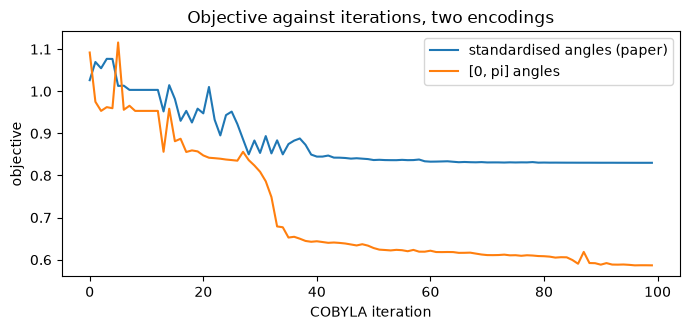

In [17]:
abl = None
if RUN_ABLATION:
    from sklearn.preprocessing import MinMaxScaler
    mm = MinMaxScaler((0, np.pi)).fit(exp["Ztr"])
    e_abl = dict(exp); e_abl["Ztr"] = mm.transform(exp["Ztr"]); e_abl["Zte"] = np.clip(mm.transform(exp["Zte"]), 0, np.pi)
    abl, pred_abl, _, hist_abl, _ = fit_eval_vqc(e_abl, SEED)
    svc_abl = SVC(kernel="rbf", random_state=SEED).fit(e_abl["Ztr"], e_abl["ytr"])
    print("VQC with [0, pi] angles:", {k: round(v, 4) for k, v in abl.items()})
    print("SVC (rbf) with [0, pi] angles: accuracy %.4f" % accuracy_score(exp["yte"], svc_abl.predict(e_abl["Zte"])))
    fig, ax = plt.subplots(figsize=(7, 3.4)); ax.plot(hist0, label="standardised angles (paper)"); ax.plot(hist_abl, label="[0, pi] angles")
    ax.set_xlabel("COBYLA iteration"); ax.set_ylabel("objective"); ax.legend(); ax.set_title("Objective against iterations, two encodings"); plt.tight_layout(); plt.show()
else:
    print("RUN_ABLATION is False (FAST_MODE): skipped.")

## 8. Side by side with the paper

A claim is "reproduced" when our value lies within 2 accuracy points (0.02 for the other fractions) of the paper's,
"not reached" or "exceeded" with the gap otherwise, and "cannot be checked" when the notebook has nothing to compare
(for example the CVAE-ID, which is not re-implemented). Our value is the mean over the draws in `SEEDS` (in `FAST_MODE`,
one draw).

In [18]:
def verdict(paper, mine, tol):
    gap = mine - paper
    if abs(gap) <= tol: return "reproduced (gap %+.4f)" % gap
    return ("not reached (gap %+.4f)" if gap < 0 else "exceeded (gap %+.4f)") % gap

V = rep[rep.model == "VQC"]
paper_tab = dict(accuracy=0.9900, precision=0.8667, recall=1.0000, f1=0.9286, auc=0.9947)
rows = []
for m, pv in paper_tab.items():
    mv = V[m].mean()
    rows.append(dict(claim=f"VQC-ID {m} (Table II)", paper=pv, notebook=round(mv, 4), verdict=verdict(pv, mv, 0.02)))
rows.append(dict(claim=f"{CV_FOLDS}-fold CV mean accuracy (text)", paper=0.9894, notebook=round(cv.VQC_acc.mean(), 4), verdict=verdict(0.9894, cv.VQC_acc.mean(), 0.02)))
rows.append(dict(claim=f"{CV_FOLDS}-fold CV recall = 1 in every fold (text)", paper=1.0, notebook=round(cv.VQC_recall.min(), 4),
                 verdict="reproduced" if cv.VQC_recall.min() >= 0.98 else "not reached (worst fold recall %.3f)" % cv.VQC_recall.min()))
hist_arr = np.array(hist0); n_stable = int(np.argmax(np.abs(hist_arr - hist_arr[-1]) <= 0.02 * abs(hist_arr[0] - hist_arr[-1]) + 1e-9)) + 1 if len(hist_arr) > 1 else 0
rows.append(dict(claim="objective stabilises after ~60 iterations (Fig. 3)", paper=60, notebook=n_stable,
                 verdict=("cannot be checked fully in FAST_MODE (only %d iterations)" % len(hist_arr)) if len(hist_arr) < 70 else
                         ("reproduced" if abs(n_stable - 60) <= 30 else "differs (flat after iteration %d)" % n_stable)))
rows.append(dict(claim="VQC-ID training + prediction time (s)", paper=205.87, notebook=round(V["seconds"].mean(), 1),
                 verdict="different machine, optimiser budget and sampler; reported only (%.0f x the paper)" % (V["seconds"].mean() / 205.87)))
svc_acc = rep[rep.model == "SVC (rbf)"]["accuracy"].mean(); rf_acc = rep[rep.model == "RandomForest"]["accuracy"].mean()
rows.append(dict(claim="VQC clearly better than classical models on the same inputs", paper="not tested", notebook="VQC %.4f vs SVC %.4f, RF %.4f" % (V.accuracy.mean(), svc_acc, rf_acc),
                 verdict="paper compares only with CVAE-ID; here: see numbers"))
if abl is not None:
    rows.append(dict(claim="extra: VQC with angles scaled to [0, pi] (main draw)", paper="not in paper", notebook="acc %.4f, recall %.4f, AUC %.4f" % (abl["accuracy"], abl["recall"], abl["auc"]),
                     verdict="reported only"))
rows.append(dict(claim="CVAE-ID row of Table II (0.9700 / 0.8000 / 0.6667 / 0.7273 / 0.9894) and 'VQC beats CVAE-ID'", paper="Table II", notebook="not re-implemented",
                 verdict="cannot be checked (no CVAE code, TensorFlow not used)"))
comp = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 80)
display(comp)

,claim,paper,notebook,verdict
0,VQC-ID accuracy (Table II),0.99,0.64,not reached (gap -0.3500)
1,VQC-ID precision (Table II),0.8667,0.1168,not reached (gap -0.7499)
2,VQC-ID recall (Table II),1.0,0.8182,not reached (gap -0.1818)
3,VQC-ID f1 (Table II),0.9286,0.2035,not reached (gap -0.7251)
4,VQC-ID auc (Table II),0.9947,0.8453,not reached (gap -0.1494)
5,5-fold CV mean accuracy (text),0.9894,0.648,not reached (gap -0.3414)
6,5-fold CV recall = 1 in every fold (text),1.0,0.6364,not reached (worst fold recall 0.636)
7,objective stabilises after ~60 iterations (Fig. 3),60,60,reproduced
8,VQC-ID training + prediction time (s),205.87,467.7,"different machine, optimiser budget and sampler; reported only (2 x the paper)"
9,VQC clearly better than classical models on the same inputs,not tested,"VQC 0.6400 vs SVC 1.0000, RF 1.0000",paper compares only with CVAE-ID; here: see numbers


## 9. Reading the paper critically

* **One tiny test set.** A 200-flow test set holds 11 to 12 attacks; the headline precision 0.8667 is 13 of 15 flagged
  flows, and recall 1.0 is 13 of 13. A single flow changes precision by 6 points. The repeated draws and the standard
  deviations above are the honest way to read these numbers; the paper reports one draw without an interval.
* **Reconnaissance attacks are easy.** The attacks of WUSTL-IIoT-2018 are scans and device enumerations: short flows with
  characteristic packet and byte counts on port 502. A random forest or an RBF-SVM on the same six standardised features is
  usually at least as accurate as the VQC (compare the tables above); the paper only compares with its own CVAE.
* **Class ratio.** 93.9 % of the flows are normal, so 94 % accuracy comes for free; the "always normal" rule is in the
  tables for that reason. Accuracy is the weakest metric here; recall, precision and AUC matter.
* **Contradictory preprocessing description.** The text says resampling happens before scaling and splitting, and also that
  attack instances were "entirely confined to the testing set" for training a *supervised* classifier. Table II is only
  consistent with a natural-ratio test set, which is what we implemented. Oversampling before the split would put copies
  of the same attack flow in training and test and inflate the scores.
* **Unbounded angles.** The six standardised features are used directly as rotation angles. Byte and packet counts are
  heavy-tailed, so a few flows get angles of tens or hundreds of radians; the rotation is periodic, so far-apart values can
  wrap onto each other. Scaling to [0, pi] (as in the other VQC notebooks of this repository) is a one-line change.
* **Cost.** Even with six qubits and 12 parameters, training on a simulator takes minutes against seconds for classical
  models, and the paper's claim of lightweight deployment is about hardware that does not yet exist for this task.
* **Reproducibility.** Seed, shots, COBYLA budget, the 1,000-flow selection, the feature-map entanglement and the
  oversampling method are not stated; each choice is listed in the table at the top.

## 10. Exercises

1. Set `FAST_MODE = False` and compare the mean and standard deviation of the VQC with the random forest. Is the gap
   larger than the spread between draws?
2. Replace the standardised angles by `MinMaxScaler((0, np.pi))` fitted on the training set (and clip the test angles).
   Does the VQC improve?
3. Change `ANSATZ_REPS` to 3 (Qiskit's default) and `FM_REPS` to 1. How do the parameter count, the circuit depth and the
   test metrics change?
4. Move the oversampling to *before* the train/test split and measure how much the test scores rise. Explain why that number
   is not trustworthy.
5. Build the paper's missing benchmark: a small conditional autoencoder (for example with scikit-learn's
   `MLPRegressor` on the concatenation of features and one-hot label) with reconstruction-error thresholding, and compare
   it with the VQC on the same test sets.